# KhushiDL - Movie Senetiment Review 🎬

In [16]:
# importing the necessary modules
import tensorflow as tf
from pathlib import Path
import matplotlib.pyplot as plt

### Data Preprocessing

In [17]:
train_path = Path('/content/aclImdb/train')

BATCH = 32
seed = 42

# training dataset
raw_train_ds = tf.keras.utils.text_dataset_from_directory(
    train_path,
    validation_split=.2,
    subset='training',
    batch_size=BATCH,
    seed=seed
)

Found 25000 files belonging to 2 classes.
Using 20000 files for training.


In [18]:
# validation dataset
raw_validation_ds = tf.keras.utils.text_dataset_from_directory(
    train_path,
    validation_split=.2,
    subset='validation',
    batch_size=BATCH,
    seed=seed
)

Found 25000 files belonging to 2 classes.
Using 5000 files for validation.


In [19]:
# test path
test_path = Path('/content/aclImdb/test')

# test dataset
raw_test_ds = tf.keras.utils.text_dataset_from_directory(
    test_path,
    batch_size=BATCH
)

Found 25000 files belonging to 2 classes.


In [20]:
# final pipeline
AUTOTUNE = tf.data.AUTOTUNE

train_ds = (
    raw_train_ds
    .cache()
    .prefetch(AUTOTUNE)
    .shuffle(buffer_size=20000)
)

validation_ds = (
    raw_validation_ds
    .cache()
    .prefetch(AUTOTUNE)
)

test_ds = (
    raw_test_ds
    .cache()
    .prefetch(AUTOTUNE)
)

## Model 🧠

In [31]:
# creating the actual model
VOCAB_SIZE = 10000
MAX_SEQUENCE_LENGTH = 250

vectorization_layer = tf.keras.layers.TextVectorization(
    max_tokens=VOCAB_SIZE,
    output_mode = 'int',
    output_sequence_length = MAX_SEQUENCE_LENGTH
)
train_text = train_ds.map(lambda text, labels: text)
vectorization_layer.adapt(train_text)

model = tf.keras.Sequential([
    vectorization_layer,
    tf.keras.layers.Embedding(
        VOCAB_SIZE + 1,
        output_dim=64,
        mask_zero=True
    ),
    tf.keras.layers.Dropout(.5),
    tf.keras.layers.Conv1D(64, 5, padding='valid', activation='relu', strides=2),
    tf.keras.layers.GlobalAveragePooling1D(),
    tf.keras.layers.Dense(1, activation='sigmoid')
])

# to check for input shape
# for text, label in train_ds.take(1):
#   model(text)

model.summary()

Model: "sequential_12"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ text_vectorization_13           │ ?                      │   0 (unbuilt) │
│ (TextVectorization)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding_12 (Embedding)        │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_12 (Dropout)            │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_12 (Conv1D)              │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d_12     │ ?                      │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

## Compiling and training the model

In [32]:
# compiling
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [33]:
# training
model_history = model.fit(
    train_ds,
    validation_data=validation_ds,
    epochs=10
)

Epoch 1/10


/usr/local/lib/python3.13/dist-packages/keras/src/layers/layer.py:982: UserWarning: Layer 'conv1d_12' (of type Conv1D) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(


625/625 ━━━━━━━━━━━━━━━━━━━━ 24s 36ms/step - accuracy: 0.7869 - loss: 0.4447 - val_accuracy: 0.8706 - val_loss: 0.3142
Epoch 2/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 40s 35ms/step - accuracy: 0.9007 - loss: 0.2579 - val_accuracy: 0.8808 - val_loss: 0.2911
Epoch 3/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 21s 33ms/step - accuracy: 0.9250 - loss: 0.1989 - val_accuracy: 0.8798 - val_loss: 0.3004
Epoch 4/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 22s 35ms/step - accuracy: 0.9355 - loss: 0.1708 - val_accuracy: 0.8764 - val_loss: 0.3127
Epoch 5/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 40s 33ms/step - accuracy: 0.9499 - loss: 0.1383 - val_accuracy: 0.8612 - val_loss: 0.4116
Epoch 6/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 22s 35ms/step - accuracy: 0.9618 - loss: 0.1109 - val_accuracy: 0.8642 - val_loss: 0.4097
Epoch 7/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 21s 33ms/step - accuracy: 0.9683 - loss: 0.0934 - val_accuracy: 0.8742 - val_loss: 0.4076
Epoch 8/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 22s 35ms/step - accuracy: 0.9755 - loss: 0.0746 - val_accurac

In [35]:
# testing model
model.evaluate(test_ds)

782/782 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.8354 - loss: 0.6761


[0.6761073470115662, 0.8353599905967712]

## Graphs 📊

In [50]:
model_history = model_history.history

AttributeError: 'dict' object has no attribute 'history'

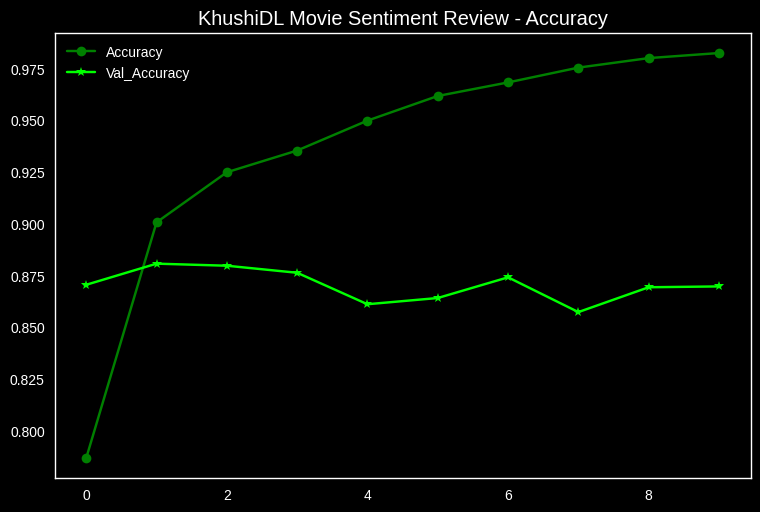

In [63]:
# Accuracy Graph
plt.title('KhushiDL Movie Sentiment Review - Accuracy')
plt.style.use('dark_background')
plt.plot(model_history['accuracy'], color='green', marker='o', label='Accuracy')
plt.plot(model_history['val_accuracy'], color='lime', marker='*', label='Val_Accuracy')
plt.grid(False)
plt.legend()
plt.show()

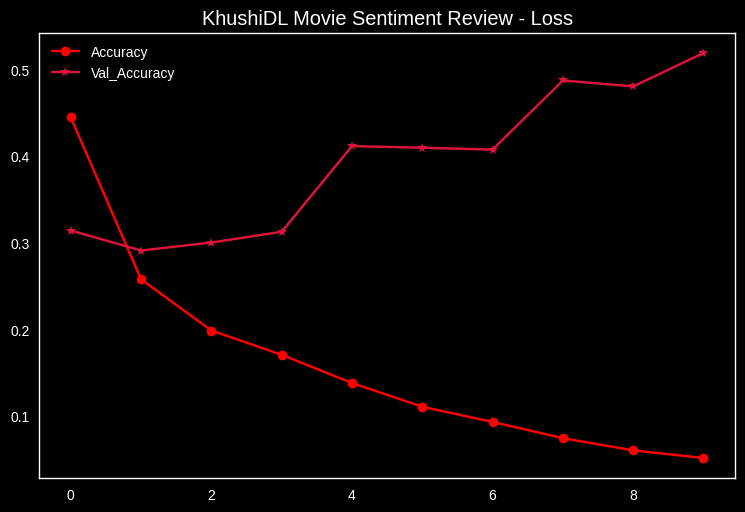

In [64]:
# Accuracy Graph
plt.title('KhushiDL Movie Sentiment Review - Loss')
plt.style.use('dark_background')
plt.plot(model_history['loss'], color='red', marker='o', label='Accuracy')
plt.plot(model_history['val_loss'], color='crimson', marker='*', label='Val_Accuracy')
plt.grid(False)
plt.legend()
plt.show()

In [66]:
model.save('model.keras') #saving the model

In [74]:
line = tf.constant(['I went and saw this movie last night after being coaxed to by a few friends of mine. I\'ll admit that I was reluctant to see it because from what I knew of Ashton Kutcher he was only able to do comedy. I was wrong. Kutcher played the character of Jake Fischer very well, and Kevin Costner played Ben Randall with such professionalism. The sign of a good movie is that it can toy with our emotions. This one did exactly that. The entire theater (which was sold out) was overcome by laughter during the first half of the movie, and were moved to tears during the second half. While exiting the theater I not only saw many women in tears, but many full grown men as well, trying desperately not to let anyone see them crying. This movie was great, and I suggest that you go see it before you judge.'])
prediction = model.predict(line)
if prediction < .5:
  print('Negative')
else:
  print("Positive")


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
Positive
